In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT_DIR = Path.cwd()
if not (ROOT_DIR / "data").exists():
    ROOT_DIR = ROOT_DIR.parent

PROD_PATH = (
    ROOT_DIR
    / "data/raw/PTProsumer/PR20/pr20_prod_2020.csv/pr20_prod_2020.csv"
)
IRRAD_PATH = (
    ROOT_DIR
    / "data/raw/PTProsumer/PR20/pr20_irrad_2020.csv/pr20_irrad_2020.csv"
)

print("Raíz del proyecto:", ROOT_DIR)
print("Producción:", PROD_PATH.exists(), PROD_PATH)
print("Irradiación:", IRRAD_PATH.exists(), IRRAD_PATH)

Raíz del proyecto: c:\Users\alfes\Desktop\Apuntes ICAI\fvaa
Producción: True c:\Users\alfes\Desktop\Apuntes ICAI\fvaa\data\raw\PTProsumer\PR20\pr20_prod_2020.csv\pr20_prod_2020.csv
Irradiación: True c:\Users\alfes\Desktop\Apuntes ICAI\fvaa\data\raw\PTProsumer\PR20\pr20_irrad_2020.csv\pr20_irrad_2020.csv


In [2]:
desde = pd.Timestamp("2020-01-01 00:00:00", tz="UTC")
hasta = pd.Timestamp("2020-01-02 00:00:00", tz="UTC")

# Producción: el CSV es grande, así que lo recorremos por bloques.
bloques = []

for bloque in pd.read_csv(
    PROD_PATH,
    usecols=["timestamp", "active_power_P1"],
    chunksize=250_000,
):
    bloque["timestamp"] = pd.to_datetime(
        bloque["timestamp"],
        utc=True,
        errors="coerce",
    )

    # El archivo está ordenado: al llegar al día siguiente podemos parar.
    if bloque["timestamp"].iloc[0] >= hasta:
        break

    mascara = (
        (bloque["timestamp"] >= desde)
        & (bloque["timestamp"] < hasta)
    )
    if mascara.any():
        bloques.append(bloque.loc[mascara].copy())

produccion_raw = pd.concat(bloques, ignore_index=True)

# Irradiación: el archivo anual es mucho más pequeño.
columnas_irradiacion = [
    "timestamp",
    "TOA",
    "Clear sky GHI",
    "Clear sky BHI",
    "Clear sky DHI",
    "Clear sky BNI",
    "GHI",
    "BHI",
    "DHI",
    "BNI",
]

irradiacion_raw = pd.read_csv(
    IRRAD_PATH,
    usecols=columnas_irradiacion,
)

irradiacion_raw["timestamp"] = pd.to_datetime(
    irradiacion_raw["timestamp"],
    utc=True,
    errors="coerce",
)

# Irradiación: timestamp marca el final del minuto.
irradiacion_raw = irradiacion_raw.loc[
    (irradiacion_raw["timestamp"] > desde)
    & (irradiacion_raw["timestamp"] <= hasta)
].copy()

print("Filas de producción:", len(produccion_raw))
print("Producción desde:", produccion_raw["timestamp"].min())
print("Producción hasta:", produccion_raw["timestamp"].max())
print("Filas de irradiación:", len(irradiacion_raw))
print("Irradiación desde:", irradiacion_raw["timestamp"].min())
print("Irradiación hasta:", irradiacion_raw["timestamp"].max())

Filas de producción: 86313
Producción desde: 2020-01-01 00:00:00+00:00
Producción hasta: 2020-01-01 23:59:59+00:00
Filas de irradiación: 1440
Irradiación desde: 2020-01-01 00:01:00+00:00
Irradiación hasta: 2020-01-02 00:00:00+00:00


In [3]:
columnas_radiacion = [
    "TOA",
    "Clear sky GHI",
    "Clear sky BHI",
    "Clear sky DHI",
    "Clear sky BNI",
    "GHI",
    "BHI",
    "DHI",
    "BNI",
]

# Esperamos un intervalo cada 15 minutos, desde las 00:15
# hasta las 00:00 del día siguiente.
cuartos_de_hora = pd.date_range(
    start=desde + pd.Timedelta(minutes=15),
    end=hasta,
    freq="15min",
    name="timestamp",
)

# Producción: media de potencia y número de lecturas válidas
# en cada intervalo [inicio, fin).
produccion_15min = (
    produccion_raw
    .resample(
        "15min",
        on="timestamp",
        closed="left",
        label="right",
    )["active_power_P1"]
    .agg(
        potencia_media_w="mean",
        registros_validos="count",
    )
    .reindex(cuartos_de_hora)
)

produccion_15min["cobertura_pct"] = (
    produccion_15min["registros_validos"] / 900 * 100
)

# Irradiación: cada timestamp indica el final del minuto.
# ceil agrupa, por ejemplo, 00:01...00:15 bajo la etiqueta 00:15.
irradiacion_trabajo = irradiacion_raw.copy()
irradiacion_trabajo["intervalo_fin"] = (
    irradiacion_trabajo["timestamp"].dt.ceil("15min")
)

irradiacion_agrupada = irradiacion_trabajo.groupby("intervalo_fin")

irradiacion_15min = irradiacion_agrupada[columnas_radiacion].sum(
    min_count=15
)

# Exigimos que los 15 minutos tengan valor en todas las columnas.
conteos = irradiacion_agrupada[columnas_radiacion].count()
irradiacion_15min["minutos_validos"] = conteos.min(axis=1)

irradiacion_15min = irradiacion_15min.reindex(cuartos_de_hora)
irradiacion_15min["cobertura_pct"] = (
    irradiacion_15min["minutos_validos"] / 15 * 100
)

# Wh/m² acumulados en el cuarto -> irradiancia media equivalente en W/m².
for columna in columnas_radiacion:
    irradiacion_15min[f"{columna}_media_w_m2"] = (
        irradiacion_15min[columna] / 0.25
    )

print("Intervalos de producción:", len(produccion_15min))
print("Intervalos de irradiación:", len(irradiacion_15min))
print("\nCobertura de producción:")
print(produccion_15min["cobertura_pct"].describe())
print("\nCobertura de irradiación:")
print(irradiacion_15min["cobertura_pct"].describe())

display(produccion_15min.head())
display(irradiacion_15min.head())

Intervalos de producción: 96
Intervalos de irradiación: 96

Cobertura de producción:
count     96.000000
mean      99.899306
std        0.032557
min       99.888889
25%       99.888889
50%       99.888889
75%       99.888889
max      100.000000
Name: cobertura_pct, dtype: float64

Cobertura de irradiación:
count     96.0
mean     100.0
std        0.0
min      100.0
25%      100.0
50%      100.0
75%      100.0
max      100.0
Name: cobertura_pct, dtype: float64


,potencia_media_w,registros_validos,cobertura_pct
timestamp,,,
2020-01-01 00:15:00+00:00,0.0,899,99.888889
2020-01-01 00:30:00+00:00,0.0,899,99.888889
2020-01-01 00:45:00+00:00,0.0,899,99.888889
2020-01-01 01:00:00+00:00,0.0,899,99.888889
2020-01-01 01:15:00+00:00,0.0,899,99.888889


,TOA,Clear sky GHI,Clear sky BHI,Clear sky DHI,Clear sky BNI,GHI,BHI,DHI,BNI,minutos_validos,cobertura_pct,TOA_media_w_m2,Clear sky GHI_media_w_m2,Clear sky BHI_media_w_m2,Clear sky DHI_media_w_m2,Clear sky BNI_media_w_m2,GHI_media_w_m2,BHI_media_w_m2,DHI_media_w_m2,BNI_media_w_m2
timestamp,,,,,,,,,,,,,,,,,,,,
2020-01-01 00:15:00+00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2020-01-01 00:30:00+00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2020-01-01 00:45:00+00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2020-01-01 01:00:00+00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2020-01-01 01:15:00+00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Filas de la tabla: 96
Índices iguales: True
Potencia ausente: 0
GHI ausente: 0
Intervalos con producción cero: 55


,potencia_media_w,cobertura_produccion_pct,GHI,GHI_media_w_m2,cobertura_irradiacion_pct
timestamp,,,,,
2020-01-01 00:15:00+00:00,0.0,99.888889,0.0,0.0,100.0
2020-01-01 00:30:00+00:00,0.0,99.888889,0.0,0.0,100.0
2020-01-01 00:45:00+00:00,0.0,99.888889,0.0,0.0,100.0
2020-01-01 01:00:00+00:00,0.0,99.888889,0.0,0.0,100.0
2020-01-01 01:15:00+00:00,0.0,99.888889,0.0,0.0,100.0
2020-01-01 01:30:00+00:00,0.0,99.888889,0.0,0.0,100.0
2020-01-01 01:45:00+00:00,0.0,99.888889,0.0,0.0,100.0
2020-01-01 02:00:00+00:00,0.0,99.888889,0.0,0.0,100.0
2020-01-01 02:15:00+00:00,0.0,99.888889,0.0,0.0,100.0


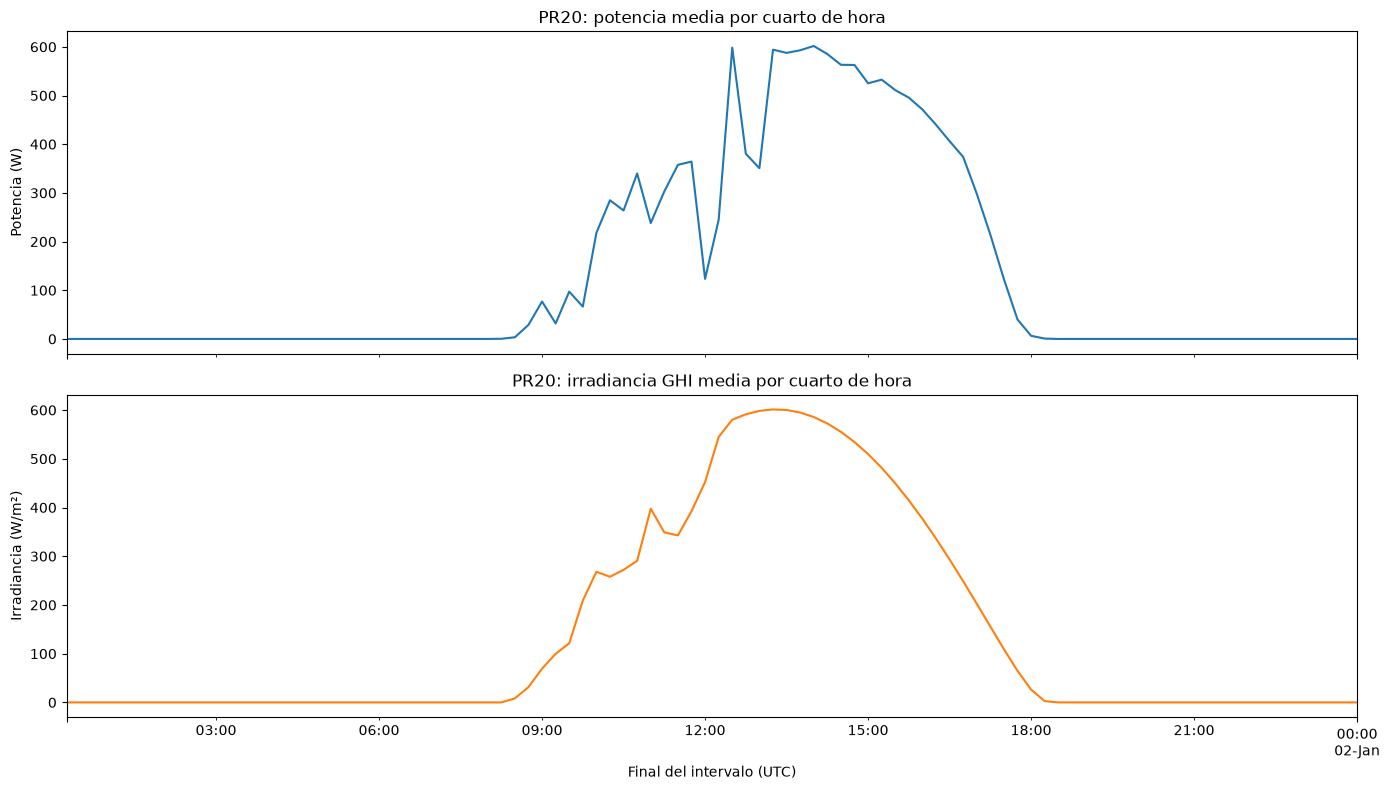

In [4]:
produccion_alineada = produccion_15min.rename(
    columns={
        "cobertura_pct": "cobertura_produccion_pct",
        "registros_validos": "registros_validos_produccion",
    }
)

irradiacion_alineada = irradiacion_15min.rename(
    columns={
        "cobertura_pct": "cobertura_irradiacion_pct",
        "minutos_validos": "minutos_validos_irradiacion",
    }
)

tabla_15min = produccion_alineada.join(
    irradiacion_alineada,
    how="outer",
).sort_index()

print("Filas de la tabla:", len(tabla_15min))
print("Índices iguales:", produccion_15min.index.equals(irradiacion_15min.index))
print("Potencia ausente:", tabla_15min["potencia_media_w"].isna().sum())
print("GHI ausente:", tabla_15min["GHI"].isna().sum())
print("Intervalos con producción cero:", tabla_15min["potencia_media_w"].eq(0).sum())

display(
    tabla_15min[
        [
            "potencia_media_w",
            "cobertura_produccion_pct",
            "GHI",
            "GHI_media_w_m2",
            "cobertura_irradiacion_pct",
        ]
    ].head(12)
)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

tabla_15min["potencia_media_w"].plot(
    ax=axes[0],
    color="tab:blue",
    title="PR20: potencia media por cuarto de hora",
)
axes[0].set_ylabel("Potencia (W)")

tabla_15min["GHI_media_w_m2"].plot(
    ax=axes[1],
    color="tab:orange",
    title="PR20: irradiancia GHI media por cuarto de hora",
)
axes[1].set_ylabel("Irradiancia (W/m²)")
axes[1].set_xlabel("Final del intervalo (UTC)")

plt.tight_layout()
plt.show()

In [5]:
datos_prueba = pd.DataFrame(index=tabla_15min.index)

# Objetivo: potencia media del intervalo que termina una hora después.
datos_prueba["objetivo_potencia_w"] = (
    tabla_15min["potencia_media_w"].shift(-4)
)

# Ejemplos de datos conocidos en el instante de predicción t.
datos_prueba["potencia_hasta_t_w"] = tabla_15min["potencia_media_w"]
datos_prueba["ghi_hasta_t_w_m2"] = tabla_15min["GHI_media_w_m2"]

# Para t = 10:00, el objetivo debe ser [10:45, 11:00).
origen = pd.Timestamp("2020-01-01 10:00:00", tz="UTC")
inicio_objetivo = origen + pd.Timedelta(minutes=45)
fin_objetivo = origen + pd.Timedelta(minutes=60)

print("Origen de predicción:", origen)
print("Intervalo objetivo:", inicio_objetivo, "a", fin_objetivo)
print("Potencia objetivo:", datos_prueba.loc[origen, "objetivo_potencia_w"], "W")

display(datos_prueba.loc[[origen]])

Origen de predicción: 2020-01-01 10:00:00+00:00
Intervalo objetivo: 2020-01-01 10:45:00+00:00 a 2020-01-01 11:00:00+00:00
Potencia objetivo: 238.12024471635152 W


,objetivo_potencia_w,potencia_hasta_t_w,ghi_hasta_t_w_m2
timestamp,,,
2020-01-01 10:00:00+00:00,238.120245,217.943159,268.1152


In [6]:
indice = tabla_15min.index
fin_objetivo = indice + pd.Timedelta(hours=1)

datos_modelo_demo = pd.DataFrame(index=indice)

# Objetivo: el intervalo que termina una hora después del origen.
datos_modelo_demo["objetivo_potencia_w"] = (
    tabla_15min["potencia_media_w"].shift(-4)
)

# Producción disponible hasta el origen y retardos históricos.
datos_modelo_demo["potencia_hasta_origen_w"] = (
    tabla_15min["potencia_media_w"]
)
datos_modelo_demo["potencia_15m_antes_w"] = (
    tabla_15min["potencia_media_w"].shift(1)
)
datos_modelo_demo["potencia_1h_antes_w"] = (
    tabla_15min["potencia_media_w"].shift(4)
)

# Irradiación observada hasta el origen y retardos históricos.
datos_modelo_demo["ghi_hasta_origen_w_m2"] = (
    tabla_15min["GHI_media_w_m2"]
)
datos_modelo_demo["ghi_15m_antes_w_m2"] = (
    tabla_15min["GHI_media_w_m2"].shift(1)
)
datos_modelo_demo["ghi_1h_antes_w_m2"] = (
    tabla_15min["GHI_media_w_m2"].shift(4)
)

# Calendario del final del intervalo que queremos predecir.
datos_modelo_demo["hora_fin_objetivo"] = fin_objetivo.hour
datos_modelo_demo["mes_fin_objetivo"] = fin_objetivo.month

origen = pd.Timestamp("2020-01-01 10:00:00", tz="UTC")

print("Origen:", origen)
print("Intervalo objetivo:", origen + pd.Timedelta(minutes=45),
      "a", origen + pd.Timedelta(hours=1))
display(datos_modelo_demo.loc[[origen]])

Origen: 2020-01-01 10:00:00+00:00
Intervalo objetivo: 2020-01-01 10:45:00+00:00 a 2020-01-01 11:00:00+00:00


,objetivo_potencia_w,potencia_hasta_origen_w,potencia_15m_antes_w,potencia_1h_antes_w,ghi_hasta_origen_w_m2,ghi_15m_antes_w_m2,ghi_1h_antes_w_m2,hora_fin_objetivo,mes_fin_objetivo
timestamp,,,,,,,,,
2020-01-01 10:00:00+00:00,238.120245,217.943159,66.378977,76.905784,268.1152,209.072,69.2112,11,1


In [7]:
def agregar_csv_produccion_por_bloques(
    ruta,
    cobertura_minima=99.0,
    chunksize=1_000_000,
):
    partes = []
    primera_fecha = None
    ultima_fecha = None

    for bloque in pd.read_csv(
        ruta,
        usecols=["timestamp", "active_power_P1"],
        chunksize=chunksize,
    ):
        bloque["timestamp"] = pd.to_datetime(
            bloque["timestamp"],
            utc=True,
            errors="raise",
        )

        if primera_fecha is None:
            primera_fecha = bloque["timestamp"].iloc[0]
        ultima_fecha = bloque["timestamp"].iloc[-1]

        parcial = (
            bloque
            .set_index("timestamp")
            .resample(
                "15min",
                closed="left",
                label="right",
            )["active_power_P1"]
            .agg(
                potencia_suma_w="sum",
                registros_validos="count",
            )
        )
        partes.append(parcial)

    # Sumamos las partes de los cuartos que hayan quedado
    # divididos entre dos bloques de lectura.
    agregado = pd.concat(partes).groupby(level=0).sum()
    agregado = agregado.sort_index()

    # Reponemos en la rejilla los cuartos sin ninguna lectura.
    primer_cuarto_fin = primera_fecha.floor("15min") + pd.Timedelta(minutes=15)
    ultimo_cuarto_fin = ultima_fecha.floor("15min") + pd.Timedelta(minutes=15)

    rejilla = pd.date_range(
        start=primer_cuarto_fin,
        end=ultimo_cuarto_fin,
        freq="15min",
        name="timestamp",
    )
    agregado = agregado.reindex(rejilla, fill_value=0)

    agregado["potencia_media_w"] = (
        agregado["potencia_suma_w"]
        / agregado["registros_validos"].replace(0, pd.NA)
    )
    agregado["cobertura_pct"] = (
        agregado["registros_validos"] / 900 * 100
    )
    agregado["intervalo_valido"] = (
        agregado["cobertura_pct"] >= cobertura_minima
    )
    agregado.loc[
        ~agregado["intervalo_valido"],
        "potencia_media_w",
    ] = pd.NA

    return agregado

In [8]:
import tempfile

with tempfile.TemporaryDirectory() as carpeta_temporal:
    ruta_demo = Path(carpeta_temporal) / "produccion_demo.csv"
    produccion_raw.to_csv(ruta_demo, index=False)

    produccion_demo_bloques = agregar_csv_produccion_por_bloques(
        ruta_demo,
        chunksize=10_000,
    )

referencia = produccion_15min["potencia_media_w"].reindex(
    produccion_demo_bloques.index
)

diferencia = (
    produccion_demo_bloques["potencia_media_w"] - referencia
).abs()

print("Cuartos agregados:", len(produccion_demo_bloques))
print("Mayor diferencia frente a la agregación anterior (W):",
      diferencia.max())
print("Cobertura mínima:", produccion_demo_bloques["cobertura_pct"].min())
print("Cobertura máxima:", produccion_demo_bloques["cobertura_pct"].max())

display(produccion_demo_bloques.head())

Cuartos agregados: 96
Mayor diferencia frente a la agregación anterior (W): 0.0
Cobertura mínima: 99.8888888888889
Cobertura máxima: 100.0


,potencia_suma_w,registros_validos,potencia_media_w,cobertura_pct,intervalo_valido
timestamp,,,,,
2020-01-01 00:15:00+00:00,0.0,899,0.0,99.888889,True
2020-01-01 00:30:00+00:00,0.0,899,0.0,99.888889,True
2020-01-01 00:45:00+00:00,0.0,899,0.0,99.888889,True
2020-01-01 01:00:00+00:00,0.0,899,0.0,99.888889,True
2020-01-01 01:15:00+00:00,0.0,899,0.0,99.888889,True


In [9]:
import time

inicio_lectura = time.perf_counter()

produccion_2020_15min = agregar_csv_produccion_por_bloques(
    PROD_PATH,
    cobertura_minima=99.0,
    chunksize=1_000_000,
)

print(f"Tiempo: {(time.perf_counter() - inicio_lectura) / 60:.1f} minutos")
print("Intervalos:", len(produccion_2020_15min))
print("Desde:", produccion_2020_15min.index.min())
print("Hasta:", produccion_2020_15min.index.max())
print("Cobertura media:",
      round(produccion_2020_15min["cobertura_pct"].mean(), 3), "%")
print("Intervalos con cobertura inferior al 99 %:",
      (~produccion_2020_15min["intervalo_valido"]).sum())

Tiempo: 0.4 minutos
Intervalos: 35136
Desde: 2020-01-01 00:15:00+00:00
Hasta: 2021-01-01 00:00:00+00:00
Cobertura media: 99.872 %
Intervalos con cobertura inferior al 99 %: 43


In [10]:
irradiacion_2020_raw = pd.read_csv(
    IRRAD_PATH,
    usecols=columnas_irradiacion,
)

irradiacion_2020_raw["timestamp"] = pd.to_datetime(
    irradiacion_2020_raw["timestamp"],
    utc=True,
    errors="raise",
)

# Asignamos cada minuto al cuarto de hora en el que termina.
irradiacion_2020_raw["intervalo_fin"] = (
    irradiacion_2020_raw["timestamp"].dt.ceil("15min")
)

grupos_irradiacion = irradiacion_2020_raw.groupby("intervalo_fin")

# Suma de los valores de los quince minutos, en Wh/m².
irradiacion_2020_15min = grupos_irradiacion[columnas_radiacion].sum(
    min_count=15
)

# Un minuto cuenta como válido si tiene dato en todas las variables.
conteos_irradiacion = grupos_irradiacion[columnas_radiacion].count()
irradiacion_2020_15min["minutos_validos"] = (
    conteos_irradiacion.min(axis=1)
)

# La rejilla de producción define los intervalos que vamos a usar.
irradiacion_2020_15min = irradiacion_2020_15min.reindex(
    produccion_2020_15min.index
)
irradiacion_2020_15min["minutos_validos"] = (
    irradiacion_2020_15min["minutos_validos"].fillna(0)
)
irradiacion_2020_15min["cobertura_pct"] = (
    irradiacion_2020_15min["minutos_validos"] / 15 * 100
)

# Solo convertimos a irradiancia media los cuartos con 15 minutos válidos.
for columna in columnas_radiacion:
    irradiacion_2020_15min[f"{columna}_media_w_m2"] = (
        irradiacion_2020_15min[columna] / 0.25
    ).where(irradiacion_2020_15min["minutos_validos"] == 15)

print("Filas de irradiación agregada:", len(irradiacion_2020_15min))
print("Índices alineados:",
      produccion_2020_15min.index.equals(irradiacion_2020_15min.index))
print("Cobertura media de irradiación:",
      round(irradiacion_2020_15min["cobertura_pct"].mean(), 3), "%")
print("Cuartos con menos de 15 minutos válidos:",
      (irradiacion_2020_15min["minutos_validos"] < 15).sum())

display(irradiacion_2020_15min.head())

Filas de irradiación agregada: 35136
Índices alineados: True
Cobertura media de irradiación: 100.0 %
Cuartos con menos de 15 minutos válidos: 1


,TOA,Clear sky GHI,Clear sky BHI,Clear sky DHI,Clear sky BNI,GHI,BHI,DHI,BNI,minutos_validos,cobertura_pct,TOA_media_w_m2,Clear sky GHI_media_w_m2,Clear sky BHI_media_w_m2,Clear sky DHI_media_w_m2,Clear sky BNI_media_w_m2,GHI_media_w_m2,BHI_media_w_m2,DHI_media_w_m2,BNI_media_w_m2
timestamp,,,,,,,,,,,,,,,,,,,,
2020-01-01 00:15:00+00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2020-01-01 00:30:00+00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2020-01-01 00:45:00+00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2020-01-01 01:00:00+00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2020-01-01 01:15:00+00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [11]:
print("Máximo GHI en el CSV original:", irradiacion_2020_raw["GHI"].max())
print("Lecturas GHI positivas en el CSV:",
      (irradiacion_2020_raw["GHI"] > 0).sum())
print("Máximo GHI agregado:", irradiacion_2020_15min["GHI"].max())
print("Cuartos con GHI positivo:",
      (irradiacion_2020_15min["GHI"] > 0).sum())

display(
    irradiacion_2020_15min.loc[
        "2020-06-21 11:00:00+00:00":"2020-06-21 14:00:00+00:00",
        ["GHI", "GHI_media_w_m2", "minutos_validos", "cobertura_pct"],
    ]
)

Máximo GHI en el CSV original: 17.466
Lecturas GHI positivas en el CSV: 263791
Máximo GHI agregado: 261.8871
Cuartos con GHI positivo: 17912


,GHI,GHI_media_w_m2,minutos_validos,cobertura_pct
timestamp,,,,
2020-06-21 11:00:00+00:00,220.2201,880.8804,15,100.0
2020-06-21 11:15:00+00:00,228.1193,912.4772,15,100.0
2020-06-21 11:30:00+00:00,235.1995,940.7980,15,100.0
2020-06-21 11:45:00+00:00,241.4275,965.7100,15,100.0
2020-06-21 12:00:00+00:00,246.7735,987.0940,15,100.0
2020-06-21 12:15:00+00:00,251.2233,1004.8932,15,100.0
2020-06-21 12:30:00+00:00,254.7554,1019.0216,15,100.0
2020-06-21 12:45:00+00:00,257.3420,1029.3680,15,100.0
2020-06-21 13:00:00+00:00,258.9703,1035.8812,15,100.0


Filas alineadas: 35136
GHI máximo: 261.8871
Cuartos con GHI positivo: 17912


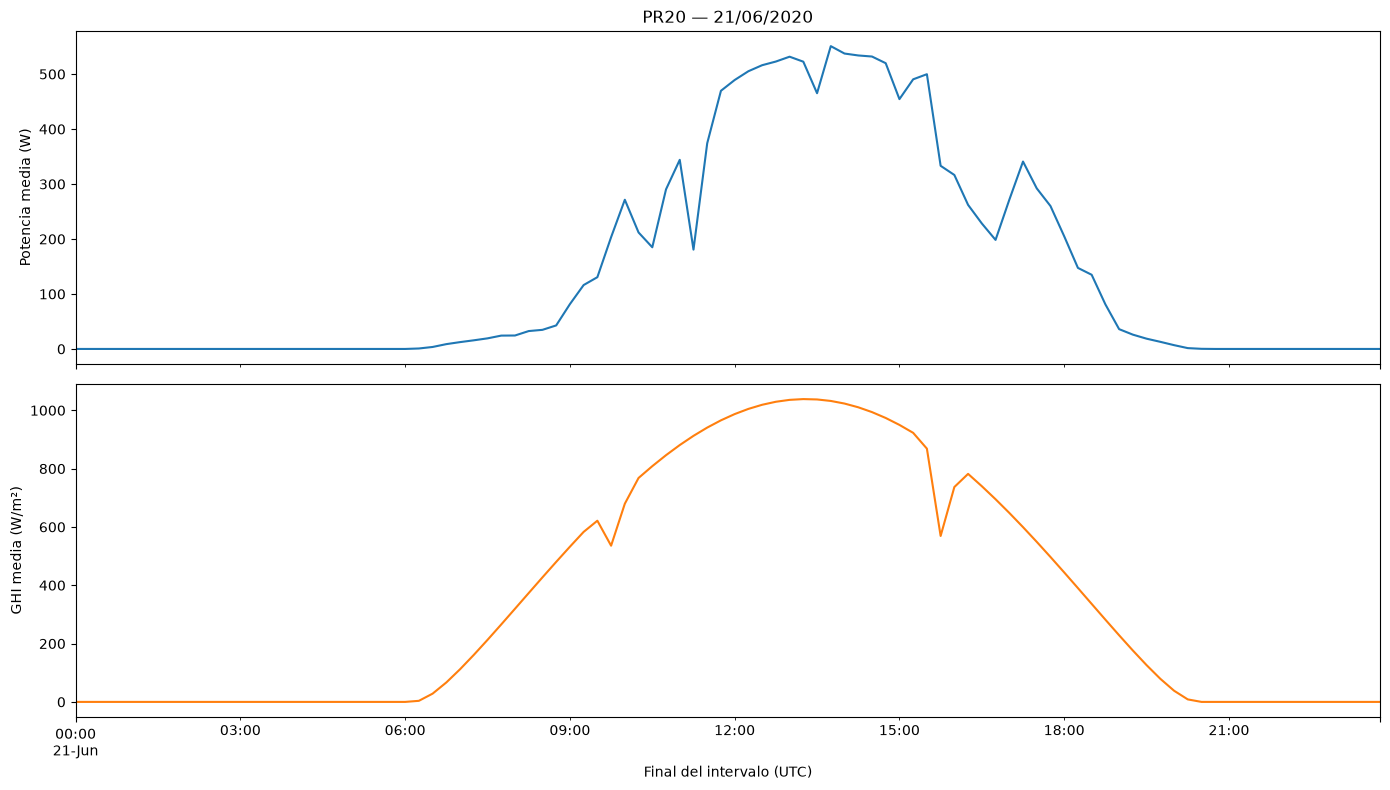

In [12]:
produccion_2020 = produccion_2020_15min.rename(
    columns={"cobertura_pct": "cobertura_produccion_pct"}
)

irradiacion_2020 = irradiacion_2020_15min.rename(
    columns={"cobertura_pct": "cobertura_irradiacion_pct"}
)

tabla_2020 = produccion_2020.join(
    irradiacion_2020,
    how="inner",
    lsuffix="_prod",
    rsuffix="_irr",
)

print("Filas alineadas:", len(tabla_2020))
print("GHI máximo:", tabla_2020["GHI"].max())
print("Cuartos con GHI positivo:", (tabla_2020["GHI"] > 0).sum())

dia = tabla_2020.loc["2020-06-21"]

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

dia["potencia_media_w"].plot(ax=axes[0], title="PR20 — 21/06/2020")
axes[0].set_ylabel("Potencia media (W)")

dia["GHI_media_w_m2"].plot(ax=axes[1], color="tab:orange")
axes[1].set_ylabel("GHI media (W/m²)")
axes[1].set_xlabel("Final del intervalo (UTC)")

plt.tight_layout()
plt.show()

In [13]:
indice = tabla_2020.index
fin_objetivo = indice + pd.Timedelta(hours=1)

datos_2020 = pd.DataFrame(index=indice)

# Objetivo: potencia media del intervalo que termina t + 60 min.
datos_2020["objetivo_potencia_w"] = (
    tabla_2020["potencia_media_w"].shift(-4)
)

# Variables conocidas en el origen o en el pasado.
datos_2020["potencia_hasta_t_w"] = tabla_2020["potencia_media_w"]
datos_2020["potencia_hace_1h_w"] = tabla_2020["potencia_media_w"].shift(4)
datos_2020["potencia_hace_24h_w"] = tabla_2020["potencia_media_w"].shift(96)

datos_2020["ghi_hasta_t_w_m2"] = tabla_2020["GHI_media_w_m2"]
datos_2020["ghi_hace_1h_w_m2"] = tabla_2020["GHI_media_w_m2"].shift(4)
datos_2020["ghi_hace_24h_w_m2"] = tabla_2020["GHI_media_w_m2"].shift(96)

# El calendario corresponde al final del intervalo objetivo.
datos_2020["hora_objetivo"] = fin_objetivo.hour
datos_2020["mes_objetivo"] = fin_objetivo.month

datos_2020["inicio_objetivo_utc"] = (
    indice + pd.Timedelta(minutes=45)
)
datos_2020["fin_objetivo_utc"] = fin_objetivo

print("Filas totales:", len(datos_2020))
print("Filas completas para el modelo:", datos_2020.dropna().shape[0])

origen = pd.Timestamp("2020-06-21 10:00:00", tz="UTC")
display(datos_2020.loc[[origen]])

Filas totales: 35136
Filas completas para el modelo: 34875


,objetivo_potencia_w,potencia_hasta_t_w,potencia_hace_1h_w,potencia_hace_24h_w,ghi_hasta_t_w_m2,ghi_hace_1h_w_m2,ghi_hace_24h_w_m2,hora_objetivo,mes_objetivo,inicio_objetivo_utc,fin_objetivo_utc
timestamp,,,,,,,,,,,
2020-06-21 10:00:00+00:00,344.020467,271.403782,81.531257,266.990444,679.7324,532.2616,727.3028,11,6,2020-06-21 10:45:00+00:00,2020-06-21 11:00:00+00:00


In [14]:
# Auditoría temporal de los timestamps originales
diferencias = irradiacion_2020_raw["timestamp"].diff()

print("=== IRRADIACIÓN ORIGINAL ===")
print("Filas:", len(irradiacion_2020_raw))
print("Desde:", irradiacion_2020_raw["timestamp"].min())
print("Hasta:", irradiacion_2020_raw["timestamp"].max())
print("Timestamps duplicados:",
      irradiacion_2020_raw["timestamp"].duplicated().sum())
print("Timestamps desordenados:", (diferencias < pd.Timedelta(0)).sum())
print("Huecos mayores de un minuto:",
      (diferencias > pd.Timedelta(minutes=1)).sum())

# Resumen de cobertura de los cuartos de hora
cobertura = irradiacion_2020_15min["cobertura_pct"]

print("\n=== COBERTURA A 15 MINUTOS ===")
print("Intervalos:", len(irradiacion_2020_15min))
print("Cobertura media:", round(cobertura.mean(), 3), "%")

for umbral in [90, 95, 99, 99.5, 100]:
    porcentaje = (cobertura >= umbral).mean() * 100
    print(f"Intervalos con cobertura >= {umbral}%: {porcentaje:.2f}%")

# Resumen por variable; los valores agregados están en Wh/m² por cuarto.
filas_resumen = []

for columna in columnas_radiacion:
    valores = irradiacion_2020_15min[columna].where(
        irradiacion_2020_15min["minutos_validos"] == 15
    )

    filas_resumen.append({
        "variable": columna,
        "cuartos_completos": int(valores.notna().sum()),
        "ceros": int(valores.eq(0).sum()),
        "mínimo_Wh_m2": valores.min(),
        "máximo_Wh_m2": valores.max(),
        "media_Wh_m2": valores.mean(),
    })

resumen_irradiacion_2020 = pd.DataFrame(filas_resumen)
display(resumen_irradiacion_2020)

=== IRRADIACIÓN ORIGINAL ===
Filas: 527040
Desde: 2020-01-01 00:00:00+00:00
Hasta: 2020-12-31 23:59:00+00:00
Timestamps duplicados: 0
Timestamps desordenados: 0
Huecos mayores de un minuto: 0

=== COBERTURA A 15 MINUTOS ===
Intervalos: 35136
Cobertura media: 100.0 %
Intervalos con cobertura >= 90%: 100.00%
Intervalos con cobertura >= 95%: 100.00%
Intervalos con cobertura >= 99%: 100.00%
Intervalos con cobertura >= 99.5%: 100.00%
Intervalos con cobertura >= 100%: 100.00%


,variable,cuartos_completos,ceros,mínimo_Wh_m2,máximo_Wh_m2,media_Wh_m2
0,TOA,35135,17223,0.0,325.5686,89.069920
1,Clear sky GHI,35135,17223,0.0,261.9773,64.815908
2,Clear sky BHI,35135,17227,0.0,241.5077,52.707015
3,Clear sky DHI,35135,17223,0.0,84.1302,12.108894
4,Clear sky BNI,35135,17462,0.0,253.1598,86.335685
5,GHI,35135,17223,0.0,261.8871,51.340688
6,BHI,35135,17845,0.0,241.1158,33.746467
7,DHI,35135,17223,0.0,130.9077,17.594222
8,BNI,35135,18002,0.0,253.1598,55.479491


In [15]:
IRRAD_DIR = ROOT_DIR / "data/raw/PTProsumer/PR20"

rutas_irradiacion = sorted(
    ruta
    for ruta in IRRAD_DIR.rglob("pr20_irrad_*.csv")
    if ruta.is_file()
)

def procesar_irradiacion_anual(ruta):
    df = pd.read_csv(
        ruta,
        usecols=columnas_irradiacion,
    )

    df["timestamp"] = pd.to_datetime(
        df["timestamp"],
        utc=True,
        errors="raise",
    )

    timestamps = df["timestamp"]
    diferencias = timestamps.diff()

    if timestamps.duplicated().any():
        raise ValueError(f"Hay timestamps duplicados en {ruta.name}")

    if not timestamps.is_monotonic_increasing:
        raise ValueError(f"Los timestamps están desordenados en {ruta.name}")

    df["intervalo_fin"] = timestamps.dt.ceil("15min")
    grupos = df.groupby("intervalo_fin")

    # Exigimos los 15 minutos para considerar completo el valor agregado.
    agregado = grupos[columnas_radiacion].sum(min_count=15)
    conteos = grupos[columnas_radiacion].count()
    agregado["minutos_validos"] = conteos.min(axis=1)

    # Hacemos explícitos también los intervalos sin lecturas.
    indice_completo = pd.date_range(
        start=timestamps.iloc[0].ceil("15min"),
        end=timestamps.iloc[-1].ceil("15min"),
        freq="15min",
        name="timestamp",
    )
    agregado = agregado.reindex(indice_completo)
    agregado["minutos_validos"] = agregado["minutos_validos"].fillna(0)
    agregado["cobertura_pct"] = agregado["minutos_validos"] / 15 * 100
    agregado["intervalo_valido"] = agregado["minutos_validos"] == 15

    for columna in columnas_radiacion:
        agregado[f"{columna}_media_w_m2"] = (
            agregado[columna] / 0.25
        ).where(agregado["intervalo_valido"])

    anio = int(ruta.stem.split("_")[-1])

    auditoria = {
        "año": anio,
        "filas_originales": len(df),
        "timestamp_inicial": timestamps.iloc[0],
        "timestamp_final": timestamps.iloc[-1],
        "duplicados": int(timestamps.duplicated().sum()),
        "desordenados": int((diferencias < pd.Timedelta(0)).sum()),
        "huecos_mayores_a_1_min": int(
            (diferencias > pd.Timedelta(minutes=1)).sum()
        ),
        "intervalos_15min": len(agregado),
        "cobertura_media_pct": agregado["cobertura_pct"].mean(),
        "intervalos_completos": int(agregado["intervalo_valido"].sum()),
    }

    return agregado, auditoria


irradiacion_por_ano = {}
resumen_anual_irradiacion = []

for ruta in rutas_irradiacion:
    agregado, auditoria = procesar_irradiacion_anual(ruta)
    irradiacion_por_ano[auditoria["año"]] = agregado
    resumen_anual_irradiacion.append(auditoria)

resumen_anual_irradiacion = pd.DataFrame(resumen_anual_irradiacion)
display(resumen_anual_irradiacion)

,año,filas_originales,timestamp_inicial,timestamp_final,duplicados,desordenados,huecos_mayores_a_1_min,intervalos_15min,cobertura_media_pct,intervalos_completos
0,2019,57600,2019-11-22 00:00:00+00:00,2019-12-31 23:59:00+00:00,0,0,0,3841,99.973965,3839
1,2020,527040,2020-01-01 00:00:00+00:00,2020-12-31 23:59:00+00:00,0,0,0,35137,99.997154,35135
2,2021,525600,2021-01-01 00:00:00+00:00,2021-12-31 23:59:00+00:00,0,0,0,35041,99.997146,35039
3,2022,525600,2022-01-01 00:00:00+00:00,2022-12-31 23:59:00+00:00,0,0,0,35041,99.997146,35039
4,2023,525600,2023-01-01 00:00:00+00:00,2023-12-31 23:59:00+00:00,0,0,0,35041,99.997146,35039


In [16]:
for anio, tabla in irradiacion_por_ano.items():
    incompletos = tabla.loc[~tabla["intervalo_valido"]]

    indices_extremos = [tabla.index[0], tabla.index[-1]]
    incompletos_interiores = incompletos.loc[
        ~incompletos.index.isin(indices_extremos)
    ]

    print(
        f"{anio}: {len(incompletos)} cuartos incompletos; "
        f"{len(incompletos_interiores)} en mitad del archivo"
    )

    display(
        incompletos[
            ["minutos_validos", "cobertura_pct"]
        ]
    )

2019: 2 cuartos incompletos; 0 en mitad del archivo


,minutos_validos,cobertura_pct
timestamp,,
2019-11-22 00:00:00+00:00,1,6.666667
2020-01-01 00:00:00+00:00,14,93.333333


2020: 2 cuartos incompletos; 0 en mitad del archivo


,minutos_validos,cobertura_pct
timestamp,,
2020-01-01 00:00:00+00:00,1,6.666667
2021-01-01 00:00:00+00:00,14,93.333333


2021: 2 cuartos incompletos; 0 en mitad del archivo


,minutos_validos,cobertura_pct
timestamp,,
2021-01-01 00:00:00+00:00,1,6.666667
2022-01-01 00:00:00+00:00,14,93.333333


2022: 2 cuartos incompletos; 0 en mitad del archivo


,minutos_validos,cobertura_pct
timestamp,,
2022-01-01 00:00:00+00:00,1,6.666667
2023-01-01 00:00:00+00:00,14,93.333333


2023: 2 cuartos incompletos; 0 en mitad del archivo


,minutos_validos,cobertura_pct
timestamp,,
2023-01-01 00:00:00+00:00,1,6.666667
2024-01-01 00:00:00+00:00,14,93.333333


In [17]:
filas_cobertura = []

for anio, tabla in irradiacion_por_ano.items():
    cobertura = tabla["cobertura_pct"]
    fila = {
        "año": anio,
        "intervalos": len(tabla),
        "cobertura_media_pct": cobertura.mean(),
    }

    for umbral in [90, 95, 99, 99.5, 100]:
        nombre = str(umbral).replace(".", "_")
        cantidad = int((cobertura >= umbral).sum())
        fila[f"intervalos_ge_{nombre}_pct"] = cantidad
        fila[f"porcentaje_ge_{nombre}_pct"] = (
            cantidad / len(tabla) * 100
        )

    filas_cobertura.append(fila)

cobertura_irradiacion_anual = (
    pd.DataFrame(filas_cobertura)
    .sort_values("año")
    .reset_index(drop=True)
)

display(cobertura_irradiacion_anual.round(2))

,año,intervalos,cobertura_media_pct,intervalos_ge_90_pct,porcentaje_ge_90_pct,intervalos_ge_95_pct,porcentaje_ge_95_pct,intervalos_ge_99_pct,porcentaje_ge_99_pct,intervalos_ge_99_5_pct,porcentaje_ge_99_5_pct,intervalos_ge_100_pct,porcentaje_ge_100_pct
0,2019,3841,99.97,3840,99.97,3839,99.95,3839,99.95,3839,99.95,3839,99.95
1,2020,35137,100.00,35136,100.00,35135,99.99,35135,99.99,35135,99.99,35135,99.99
2,2021,35041,100.00,35040,100.00,35039,99.99,35039,99.99,35039,99.99,35039,99.99
3,2022,35041,100.00,35040,100.00,35039,99.99,35039,99.99,35039,99.99,35039,99.99
4,2023,35041,100.00,35040,100.00,35039,99.99,35039,99.99,35039,99.99,35039,99.99


In [18]:
directorio_datos = (
    ROOT_DIR
    / "data/interim/PTProsumer/PR20/irradiacion_15min"
)
directorio_informes = ROOT_DIR / "reports/data_quality"

directorio_datos.mkdir(parents=True, exist_ok=True)
directorio_informes.mkdir(parents=True, exist_ok=True)

cobertura_por_intervalo = []

for anio, tabla in sorted(irradiacion_por_ano.items()):
    ruta_salida = directorio_datos / f"pr20_irradiacion_15min_{anio}.csv"

    tabla.to_csv(ruta_salida, index_label="timestamp")

    informe_intervalos = tabla[
        ["minutos_validos", "cobertura_pct", "intervalo_valido"]
    ].copy()
    informe_intervalos["año"] = anio
    cobertura_por_intervalo.append(
        informe_intervalos.reset_index()
    )

cobertura_por_intervalo = pd.concat(
    cobertura_por_intervalo,
    ignore_index=True,
)

ruta_resumen = (
    directorio_informes
    / "pr20_irradiacion_cobertura_resumen.csv"
)
ruta_intervalos = (
    directorio_informes
    / "pr20_irradiacion_cobertura_15min.csv"
)

cobertura_irradiacion_anual.to_csv(ruta_resumen, index=False)
cobertura_por_intervalo.to_csv(ruta_intervalos, index=False)

print("Tablas agregadas guardadas en:", directorio_datos)
print("Resumen anual guardado en:", ruta_resumen)
print("Cobertura por intervalo guardada en:", ruta_intervalos)

Tablas agregadas guardadas en: c:\Users\alfes\Desktop\Apuntes ICAI\fvaa\data\interim\PTProsumer\PR20\irradiacion_15min
Resumen anual guardado en: c:\Users\alfes\Desktop\Apuntes ICAI\fvaa\reports\data_quality\pr20_irradiacion_cobertura_resumen.csv
Cobertura por intervalo guardada en: c:\Users\alfes\Desktop\Apuntes ICAI\fvaa\reports\data_quality\pr20_irradiacion_cobertura_15min.csv


In [19]:
display(cobertura_irradiacion_anual.round(2))

for anio, tabla in sorted(irradiacion_por_ano.items()):
    incompletos = tabla.loc[~tabla["intervalo_valido"]]
    bordes = [tabla.index[0], tabla.index[-1]]
    incompletos_interiores = incompletos.loc[
        ~incompletos.index.isin(bordes)
    ]

    print(
        f"{anio}: {len(tabla)} intervalos; "
        f"{len(incompletos_interiores)} incompletos dentro del año"
    )

print("\nArchivos agregados:")
for ruta in sorted(directorio_datos.glob("*.csv")):
    print(f"{ruta.name}: {ruta.stat().st_size / 1_000_000:.2f} MB")

print("\nInformes:")
print(ruta_resumen.exists(), ruta_resumen)
print(ruta_intervalos.exists(), ruta_intervalos)

,año,intervalos,cobertura_media_pct,intervalos_ge_90_pct,porcentaje_ge_90_pct,intervalos_ge_95_pct,porcentaje_ge_95_pct,intervalos_ge_99_pct,porcentaje_ge_99_pct,intervalos_ge_99_5_pct,porcentaje_ge_99_5_pct,intervalos_ge_100_pct,porcentaje_ge_100_pct
0,2019,3841,99.97,3840,99.97,3839,99.95,3839,99.95,3839,99.95,3839,99.95
1,2020,35137,100.00,35136,100.00,35135,99.99,35135,99.99,35135,99.99,35135,99.99
2,2021,35041,100.00,35040,100.00,35039,99.99,35039,99.99,35039,99.99,35039,99.99
3,2022,35041,100.00,35040,100.00,35039,99.99,35039,99.99,35039,99.99,35039,99.99
4,2023,35041,100.00,35040,100.00,35039,99.99,35039,99.99,35039,99.99,35039,99.99


2019: 3841 intervalos; 0 incompletos dentro del año
2020: 35137 intervalos; 0 incompletos dentro del año
2021: 35041 intervalos; 0 incompletos dentro del año
2022: 35041 intervalos; 0 incompletos dentro del año
2023: 35041 intervalos; 0 incompletos dentro del año

Archivos agregados:
pr20_irradiacion_15min_2019.csv: 0.58 MB
pr20_irradiacion_15min_2020.csv: 5.60 MB
pr20_irradiacion_15min_2021.csv: 5.59 MB
pr20_irradiacion_15min_2022.csv: 5.58 MB
pr20_irradiacion_15min_2023.csv: 5.58 MB

Informes:
True c:\Users\alfes\Desktop\Apuntes ICAI\fvaa\reports\data_quality\pr20_irradiacion_cobertura_resumen.csv
True c:\Users\alfes\Desktop\Apuntes ICAI\fvaa\reports\data_quality\pr20_irradiacion_cobertura_15min.csv
